# 14-1. 금 가격의 d 후보 (데이터 특징)

주요변수에 쓴 d 판정 규칙(`12-1`)을 금 가격(실제가) 한 변수에 적용한다. 성능은 보지 않는다.

**판정 규칙** (유의수준 0.05): ADF, DF-GLS, PP(귀무가설 '단위근')와 KPSS(귀무가설 '정상')

| 판정 | 조건 |
|---|---|
| d=1 | 단위근 검정 3개 모두 기각 못함 **그리고** KPSS가 정상을 기각 |
| d=0 | 단위근 검정 3개 중 2개 이상 기각 **그리고** KPSS가 정상을 기각 못함 |
| 애매 | 그 외 |

차분 후 ACF lag-1이 -0.5보다 작으면 과차분 경고를 붙인다. d는 모든 origin에 고정하므로 전체 데이터로 정하고, 백테스트의 낙관 편향은 origin별 판정(4절)으로 점검한다.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch.unitroot import ADF, DFGLS, PhillipsPerron, KPSS
from statsmodels.tsa.stattools import acf
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

raw = pd.read_csv("../../data/gold/gold_price.csv", encoding="utf-8-sig").rename(columns={"분기": "quarter", "실제가": "gold_price"})
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
data = raw[["quarter", "gold_price"]].dropna().reset_index(drop=True)
y, q = data["gold_price"].values.astype(float), data["quarter"].values
ALPHA, H = 0.05, 4
print(f"금 가격: {len(y)}개, {q[0]} ~ {q[-1]}, 최솟값 {y.min():.0f}, 최댓값 {y.max():.0f}")


def tests(x):
    out = {}
    for nm, T in [("ADF", lambda z: ADF(z, method="aic")), ("DF-GLS", lambda z: DFGLS(z, method="aic")), ("PP", PhillipsPerron), ("KPSS", KPSS)]:
        try:
            out[nm] = float(T(x).pvalue)
        except Exception:
            out[nm] = np.nan
    return out


def verdict(x):
    t = tests(x)
    nrej = sum(t[k] < ALPHA for k in ("ADF", "DF-GLS", "PP"))
    if nrej == 0 and t["KPSS"] < ALPHA:
        return "d=1", t, nrej
    if nrej >= 2 and t["KPSS"] >= ALPHA:
        return "d=0", t, nrej
    return "애매", t, nrej

금 가격: 64개, 2010Q1 ~ 2025Q4, 최솟값 1106, 최댓값 4135


## 1. 검정 결과

판정은 수준(원래 값) 기준이고, 1차 차분 열은 차분한 시계열이 정상인지 보는 참고용이다. 숫자는 p-value다.

In [2]:
vd, t_lvl, nr = verdict(y)
t_dif = tests(np.diff(y))
tab = pd.DataFrame({"수준": t_lvl, "1차 차분": t_dif}).T
tab["단위근 기각 수(3개 중)"] = [nr, sum(t_dif[k] < ALPHA for k in ("ADF", "DF-GLS", "PP"))]
display(tab.round(3))
a1 = acf(np.diff(y), nlags=1)[1]
print(f"판정(수준 기준): {vd}  |  차분 후 ACF lag-1 = {a1:.2f}", "(과차분 경고 없음)" if a1 > -0.5 else "(과차분 경고)")

,ADF,DF-GLS,PP,KPSS,단위근 기각 수(3개 중)
수준,1.000,0.988,1.000,0.006,0
1차 차분,0.995,0.517,0.002,0.031,1


판정(수준 기준): d=1  |  차분 후 ACF lag-1 = 0.38 (과차분 경고 없음)


## 2. 그림과 ACF

왼쪽: 수준, 가운데: 1차 차분, 오른쪽: ACF(파랑 수준, 주황 1차 차분, 점선 ±1.96/√n).

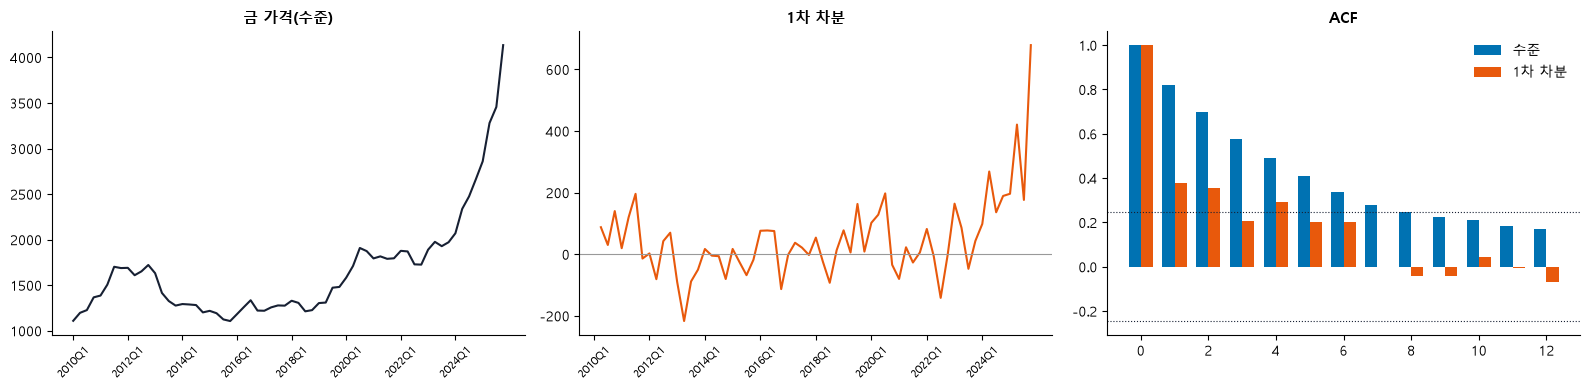

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(range(len(y)), y, color="#172033")
ax[0].set_title("금 가격(수준)", fontsize=11, fontweight="bold")
ax[1].plot(range(1, len(y)), np.diff(y), color="#E8590C")
ax[1].axhline(0, color="#999999", linewidth=0.8)
ax[1].set_title("1차 차분", fontsize=11, fontweight="bold")
for a_ in ax[:2]:
    a_.set_xticks(range(0, len(y), 8))
    a_.set_xticklabels(q[::8], rotation=45, fontsize=8)
nl = 12
ax[2].bar(np.arange(nl + 1) - 0.18, acf(y, nlags=nl), 0.36, color="#0072B2", label="수준")
ax[2].bar(np.arange(nl + 1) + 0.18, acf(np.diff(y), nlags=nl), 0.36, color="#E8590C", label="1차 차분")
ax[2].axhline(1.96 / np.sqrt(len(y)), color="#172033", linestyle=":", linewidth=0.8)
ax[2].axhline(-1.96 / np.sqrt(len(y)), color="#172033", linestyle=":", linewidth=0.8)
ax[2].legend(frameon=False)
ax[2].set_title("ACF", fontsize=11, fontweight="bold")
for a_ in ax:
    a_.spines["top"].set_visible(False)
    a_.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

## 3. 첫 35개 vs 전체

평가 시작 전 구간(첫 35개)만 쓰면 판정이 달라지는지 본다.

In [4]:
for nm, x in [("첫 35개", y[:35]), ("전체", y)]:
    v_, t_, n_ = verdict(x)
    print(f"{nm}: 판정 {v_}, 단위근 기각 {n_}/3, KPSS p={t_['KPSS']:.3f}")

첫 35개: 판정 애매, 단위근 기각 0/3, KPSS p=0.104
전체: 판정 d=1, 단위근 기각 0/3, KPSS p=0.006


## 4. origin별 판정 (전체 데이터로 정한 d의 편향 점검)

origin마다 그 시점까지의 데이터로 같은 규칙을 돌려 최종 판정과 언제 같아지는지 본다.

origin 20~ 60 판정 분포: {'애매': 33, 'd=1': 6, 'd=0': 2}
채점 origin(26개) 중 최종 판정(d=1)과 같은 비율: 23%
최종 판정과 계속 같아지는 첫 origin: 55


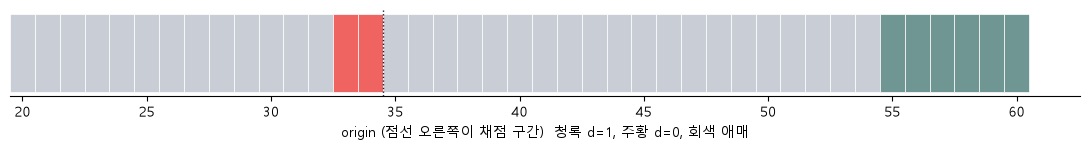

In [5]:
roll = pd.Series({o: verdict(y[:o])[0] for o in range(20, len(y) - H + 1)})
sc = roll[roll.index >= 35]
print("origin 20~", roll.index[-1], "판정 분포:", roll.value_counts().to_dict())
print(f"채점 origin({len(sc)}개) 중 최종 판정({vd})과 같은 비율: {100 * (sc == vd).mean():.0f}%")
stable = next((o for o in roll.index if (roll.loc[o:] == vd).all()), None)
print("최종 판정과 계속 같아지는 첫 origin:", stable)
col = {"d=1": "#6F9692", "d=0": "#EF6461", "애매": "#C9CED6"}
fig, ax = plt.subplots(figsize=(11, 1.6))
for o, v_ in roll.items():
    ax.barh(0, 1, left=o - 0.5, color=col[v_], edgecolor="white", linewidth=0.5)
ax.axvline(34.5, color="#172033", linestyle=":", linewidth=1)
ax.set_yticks([])
ax.set_xlabel("origin (점선 오른쪽이 채점 구간)  청록 d=1, 주황 d=0, 회색 애매")
for sp_ in ("top", "right", "left"):
    ax.spines[sp_].set_visible(False)
fig.tight_layout()
plt.show()

## 5. 결론

**금 가격은 d=1이다.** 단위근 검정 3개가 모두 단위근을 기각하지 못하고 KPSS가 정상을 기각한다(수준 p=0.006). 차분 후 ACF lag-1이 0.38로 과차분 경고는 없다.

- **origin별 판정이 최종과 다르다**: 채점 origin 26개 중 최종 판정(d=1)과 같은 비율은 23%이고, origin 55(2024Q3까지 훈련) 이후에야 계속 d=1이 나온다. 첫 35개만 쓴 판정은 애매다. 12시리즈의 d=1 변수들(X3, X6)과 같은 모양으로, 끝쪽 급등 구간(2024~25년)을 포함한 데이터에서야 d=1이 확정되어 백테스트에 낙관 편향이 있을 수 있다.
- **차분 후에도 정상성이 완전하지 않다**: 1차 차분은 PP만 단위근을 기각하고 ADF와 DF-GLS는 기각하지 못하며 KPSS도 정상을 기각한다(p=0.031). 이번 단계에서는 d=0, 1과 D=0, 1만 비교한다(12시리즈와 같은 범위).